# Aula 11 — Validação Experimental e Fechamento da AC-3 (Sprint 3)


In [1]:
!pip install -q scikit-fuzzy pytest pytest-cov

## arquivos do projeto

In [17]:
%%writefile model.py
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import skfuzzy as fuzzy
from skfuzzy import control as ctrl

def criar_sistema_fuzzy():
    """
    Define o Universo do Discurso, as Variáveis Linguísticas
    e mapear as Funções de Pertinência (Membership Functions) do problema.
    """
    # --------------------------------------------------------------------------
    # ETAPA 1: DEFINIÇÃO DOS UNIVERSOS DO DISCURSO (UNIVERSES OF DISCOURSE)
    # --------------------------------------------------------------------------
    # Antecedente 1: Impacto no Negócio (0 a 100%)
    impacto = ctrl.Antecedent(np.arange(0, 101, 1), 'impacto')

    # Antecedente 2: Explorabilidade da Falha (0 a 10)
    explorabilidade = ctrl.Antecedent(np.arange(0, 11, 1), 'explorabilidade')

    # Consequente: Urgência de Resposta/Atendimento (0 a 100%)
    urgencia = ctrl.Consequent(np.arange(0, 101, 1), 'urgencia')

    # --------------------------------------------------------------------------
    # ETAPA 2: CONFIGURAÇÃO DO MÉTODO DE DEFUZZIFICAÇÃO
    # --------------------------------------------------------------------------
    urgencia.defuzzify_method = 'centroid'

    # --------------------------------------------------------------------------
    # ETAPA 3: FUNÇÕES DE PERTINÊNCIA DA VARIÁVEL "IMPACTO" (0 a 100)
    # trimf = Triangular [início, topo_máximo, fim]
    # trapmf = Trapezoidal [início_rampa, topo_inicio, topo_fim, fim_rampa]
    # --------------------------------------------------------------------------
    impacto['baixo'] = fuzzy.trimf(impacto.universe, [0, 0, 40])
    impacto['medio'] = fuzzy.trimf(impacto.universe, [20, 50, 80])
    impacto['alto'] = fuzzy.trapmf(impacto.universe, [60, 80, 100, 100])

    # --------------------------------------------------------------------------
    # ETAPA 4: FUNÇÕES DE PERTINÊNCIA DA VARIÁVEL "EXPLORABILIDADE" (0 a 10)
    # --------------------------------------------------------------------------
    explorabilidade['baixa'] = fuzzy.trimf(explorabilidade.universe, [0, 0, 4])
    explorabilidade['moderada'] = fuzzy.trimf(explorabilidade.universe, [2, 5, 8])
    explorabilidade['alta'] = fuzzy.trimf(explorabilidade.universe, [6, 10, 10])

    # --------------------------------------------------------------------------
    # ETAPA 5: FUNÇÕES DE PERTINÊNCIA DA VARIÁVEL "URGÊNCIA" (0 a 100)
    # --------------------------------------------------------------------------
    urgencia['baixa'] = fuzzy.trimf(urgencia.universe, [0, 0, 30])
    urgencia['media'] = fuzzy.trimf(urgencia.universe, [20, 50, 70])
    urgencia['alta'] = fuzzy.trimf(urgencia.universe, [60, 80, 90])
    urgencia['critica'] = fuzzy.trapmf(urgencia.universe, [80, 90, 100, 100])

    return impacto, explorabilidade, urgencia


def gerar_graficos_pertinencia():
    """
    Visualiza graficamente os conjuntos fuzzy e salva a imagem de validação.
    """
    impacto, explorabilidade, urgencia = criar_sistema_fuzzy()

    Path("results").mkdir(exist_ok=True)

    fig, (ax0, ax1, ax2) = plt.subplots(nrows=3, figsize=(8, 8))
    impacto.view(ax=ax0)
    explorabilidade.view(ax=ax1)
    urgencia.view(ax=ax2)

    plt.tight_layout()
    plt.savefig('results/membership_functions.png')
    plt.close()
    print("Sucesso: Gráfico 'results/membership_functions.png' gerado com êxito!")


if __name__ == "__main__":
    gerar_graficos_pertinencia()

Overwriting model.py


In [18]:
%%writefile engine.py
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from skfuzzy import control as ctrl

# Importa a função de modelagem construída na Sprint 1 (Aula 09)
from model import criar_sistema_fuzzy


def construir_motor_inferencia():
    """
    Instancia o sistema fuzzy e mapeia as 9 regras de inferência (Mamdani)
    garantindo cobertura total da matriz 3x3.
    """
    # Recupera os antecedentes e consequentes configurados na Aula 09
    impacto, explorabilidade, urgencia = criar_sistema_fuzzy()

    # --------------------------------------------------------------------------
    # BASE DE REGRAS FUZZY (Mapeamento 3 x 3 = 9 Combinações)
    # Operador '&' no scikit-fuzzy representa o Fuzzy AND (Mínimo de Mamdani)
    # --------------------------------------------------------------------------

    # Bloco 1: Impacto Baixo
    regra1 = ctrl.Rule(impacto['baixo'] & explorabilidade['baixa'], urgencia['baixa'])
    regra2 = ctrl.Rule(impacto['baixo'] & explorabilidade['moderada'], urgencia['baixa'])
    regra3 = ctrl.Rule(impacto['baixo'] & explorabilidade['alta'], urgencia['media'])

    # Bloco 2: Impacto Médio
    regra4 = ctrl.Rule(impacto['medio'] & explorabilidade['baixa'], urgencia['media'])
    regra5 = ctrl.Rule(impacto['medio'] & explorabilidade['moderada'], urgencia['alta'])
    regra6 = ctrl.Rule(impacto['medio'] & explorabilidade['alta'], urgencia['alta'])

    # Bloco 3: Impacto Alto (Risco Crítico Garante Resposta Máxima)
    regra7 = ctrl.Rule(impacto['alto'] & explorabilidade['baixa'], urgencia['critica'])
    regra8 = ctrl.Rule(impacto['alto'] & explorabilidade['moderada'], urgencia['critica'])
    regra9 = ctrl.Rule(impacto['alto'] & explorabilidade['alta'], urgencia['critica'])

    # Agrupa as 9 regras no Sistema de Controle
    sistema_controle = ctrl.ControlSystem([
        regra1, regra2, regra3,
        regra4, regra5, regra6,
        regra7, regra8, regra9
    ])

    # Retorna o Simulador pronto para inferência ponta a ponta
    return ctrl.ControlSystemSimulation(sistema_controle)


def gerar_superficie_3d(simulador):
    """
    Varre todo o espaço de busca (Grid 20x20) calculando a saída de urgência
    para renderizar a Superfície de Decisão 3D em formato PNG.
    """
    # Garante que o diretório de resultados exista
    Path("results").mkdir(exist_ok=True)

    # Cria uma malha/grid numérica 20x20 cobrindo todo o universo do discurso
    # x = Impacto (0 a 100), y = Explorabilidade (0 a 10)
    x, y = np.meshgrid(np.linspace(0, 100, 20), np.linspace(0, 10, 20))
    z = np.zeros_like(x)

    # Itera sobre cada ponto do grid computando a inferência fuzzy
    for i in range(20):
        for j in range(20):
            simulador.input['impacto'] = x[i, j]
            simulador.input['explorabilidade'] = y[i, j]
            simulador.compute()
            z[i, j] = simulador.output['urgencia']

    # Configuração da figura e do eixo tridimensional 3D
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')

    # Plota a superfície contínua com mapa de cores 'viridis'
    surf = ax.plot_surface(x, y, z, cmap='viridis', edgecolor='none', alpha=0.9)

    # Personalização de títulos e eixos
    ax.set_xlabel('Impacto no Negócio (%)')
    ax.set_ylabel('Explorabilidade (0-10)')
    ax.set_zlabel('Urgência Calculada (%)')
    plt.title('Superfície de Decisão Fuzzy — SOC Autônomo')

    # Barra de cores lateral
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=5)

    plt.tight_layout()
    plt.savefig('results/superficie_decisao.png')
    plt.close()
    print("Sucesso: Imagem 'results/superficie_decisao.png' gerada com êxito!")


def simular_casos_teste(simulador):
    """
    Executa testes rápidos no console para validar a saída do sistema.
    """
    casos = [
        ("Mínimo Absoluto", 0.0, 0.0),
        ("Baixo Impacto + Alta Explorabilidade (Transição)", 10.0, 9.0),
        ("Médio Impacto + Moderado", 50.0, 5.0),
        ("Máximo Absoluto", 100.0, 10.0)
    ]

    print("\n=== SIMULAÇÕES DE TESTE DE INFERÊNCIA ===")
    for nome, imp, exp in casos:
        simulador.input['impacto'] = imp
        simulador.input['explorabilidade'] = exp
        simulador.compute()
        res = simulador.output['urgencia']
        print(f"[{nome}] -> Imp: {imp}% | Exp: {exp} => Urgência: {res:.2f}%")


if __name__ == "__main__":
    sim = construir_motor_inferencia()
    simular_casos_teste(sim)
    gerar_superficie_3d(sim)

Overwriting engine.py


In [19]:
%%writefile test_fuzzy_engine.py
# ==============================================================================
# AULA 11 — SPRINT 3 (AC-3): SUÍTE DE TESTES AUTOMATIZADOS (PYTEST)
# Objetivo: Validação de Borda, Monotonicidade e Desempenho do Motor Fuzzy
# ==============================================================================

import time
import pytest
import numpy as np
from engine import construir_motor_inferencia


@pytest.fixture
def simulador():
    """Fixture que instancia o motor de inferência compilado para os testes."""
    return construir_motor_inferencia()


def executar_inferencia(simulador, impacto, explorabilidade):
    """Função auxiliar para executar inferência com validação de entrada."""
    if not (0 <= impacto <= 100):
        raise ValueError(f"Impacto fora da escala [0, 100]: {impacto}")
    if not (0 <= explorabilidade <= 10):
        raise ValueError(f"Explorabilidade fora da escala [0, 10]: {explorabilidade}")

    simulador.input['impacto'] = impacto
    simulador.input['explorabilidade'] = explorabilidade
    simulador.compute()
    return simulador.output['urgencia']


# ------------------------------------------------------------------------------
# 1. TESTES DE LIMITES E INTERVALO DE SAÍDA
# ------------------------------------------------------------------------------
def test_saida_dentro_do_universo(simulador):
    """Garante que a saída esteja sempre no intervalo [0, 100]%."""
    casos = [(0, 0), (50, 5), (100, 10), (30, 8), (80, 2)]
    for imp, exp in casos:
        res = executar_inferencia(simulador, imp, exp)
        assert 0.0 <= res <= 100.0, f"Falha: Saída {res} fora de [0, 100] para ({imp}, {exp})"


# ------------------------------------------------------------------------------
# 2. TESTES DE MONOTONICIDADE (LÓGICA DE NEGÓCIO)
# ------------------------------------------------------------------------------
def test_monotonicidade_impacto(simulador):
    """Aumentar o impacto mantendo a explorabilidade deve AUMENTAR ou MANTER a urgência."""
    exp_fixa = 5.0
    urg_baixa = executar_inferencia(simulador, 20.0, exp_fixa)
    urg_media = executar_inferencia(simulador, 50.0, exp_fixa)
    urg_alta = executar_inferencia(simulador, 90.0, exp_fixa)

    assert urg_baixa <= urg_media <= urg_alta, (
        f"Violação de Monotonicidade: {urg_baixa:.1f} <= {urg_media:.1f} <= {urg_alta:.1f}"
    )


# ------------------------------------------------------------------------------
# 3. TESTES DE TRATAMENTO DE EXCEÇÃO (ENTRADAS INVÁLIDAS)
# ------------------------------------------------------------------------------
def test_entradas_invalidas_disparam_erro(simulador):
    """Verifica se o sistema rejeita valores fora do universo do discurso."""
    with pytest.raises(ValueError):
        executar_inferencia(simulador, -10.0, 5.0)  # Impacto negativo

    with pytest.raises(ValueError):
        executar_inferencia(simulador, 150.0, 5.0)  # Impacto > 100

    with pytest.raises(ValueError):
        executar_inferencia(simulador, 50.0, 12.0)  # Explorabilidade > 10


# ------------------------------------------------------------------------------
# 4. TESTE DE DESEMPENHO E LATÊNCIA (JIT / PERFORMANCE)
# ------------------------------------------------------------------------------
def test_latencia_inferencia(simulador):
    """Garante que 100 inferências sejam executadas em menos de 1 segundo (SLA < 10ms/op)."""
    inicio = time.time()
    for _ in range(100):
        imp = np.random.uniform(0, 100)
        exp = np.random.uniform(0, 10)
        executar_inferencia(simulador, imp, exp)
    tempo_total = time.time() - inicio

    tempo_medio_ms = (tempo_total / 100) * 1000
    print(f"\nTempo médio por inferência: {tempo_medio_ms:.3f} ms")

    assert tempo_medio_ms < 10.0, f"Inferência muito lenta: {tempo_medio_ms:.2f} ms por chamada"

Overwriting test_fuzzy_engine.py


In [20]:
%%writefile uti_triagem.py
"""Sistema fuzzy de pré-triagem de risco clínico em UTI (Mamdani, centroide)."""
import numpy as np
import skfuzzy as fuzzy
from skfuzzy import control as ctrl


def criar_sistema_triagem_uti():
    freq = ctrl.Antecedent(np.arange(40, 161, 1), "freq_cardiaca")
    spo2 = ctrl.Antecedent(np.arange(70, 101, 1), "spo2")
    risco = ctrl.Consequent(np.arange(0, 101, 1), "risco")
    risco.defuzzify_method = "centroid"

    freq["bradicardia"] = fuzzy.trimf(freq.universe, [40, 40, 60])
    freq["normal"] = fuzzy.trimf(freq.universe, [50, 75, 100])
    freq["taquicardia"] = fuzzy.trapmf(freq.universe, [90, 110, 160, 160])

    spo2["critica"] = fuzzy.trapmf(spo2.universe, [70, 70, 88, 91])
    spo2["limitrofe"] = fuzzy.trimf(spo2.universe, [89, 93, 96])
    spo2["normal"] = fuzzy.trapmf(spo2.universe, [94, 97, 100, 100])

    risco["baixo"] = fuzzy.trimf(risco.universe, [0, 0, 35])
    risco["moderado"] = fuzzy.trimf(risco.universe, [25, 50, 75])
    risco["critico"] = fuzzy.trapmf(risco.universe, [65, 85, 100, 100])

    regras = [
        ctrl.Rule(spo2["critica"], risco["critico"]),                                   # R1
        ctrl.Rule(freq["bradicardia"] & spo2["limitrofe"], risco["critico"]),           # R2
        ctrl.Rule(freq["taquicardia"] & spo2["limitrofe"], risco["critico"]),           # R3
        ctrl.Rule(freq["normal"] & spo2["limitrofe"], risco["moderado"]),               # R4
        ctrl.Rule(freq["normal"] & spo2["normal"], risco["baixo"]),                     # R5
        # R6/R7 (extensão além das 5 regras do enunciado): sem elas, FC anormal com
        # SpO2 normal não dispara nenhuma regra e o skfuzzy levanta KeyError('risco').
        ctrl.Rule(freq["bradicardia"] & spo2["normal"], risco["moderado"]),             # R6
        ctrl.Rule(freq["taquicardia"] & spo2["normal"], risco["moderado"]),             # R7
    ]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(regras))


def avaliar_paciente(simulador, bpm, spo2_val):
    if not (40 <= bpm <= 160):
        raise ValueError(f"FC fora de [40, 160] bpm: {bpm}")
    if not (70 <= spo2_val <= 100):
        raise ValueError(f"SpO2 fora de [70, 100]%: {spo2_val}")
    simulador.input["freq_cardiaca"] = bpm
    simulador.input["spo2"] = spo2_val
    simulador.compute()
    return float(simulador.output["risco"])


if __name__ == "__main__":
    sim = criar_sistema_triagem_uti()
    print("Sistema de UTI instanciado com sucesso!")
    for b, s in [(75, 98), (75, 95), (75, 89), (45, 98), (120, 92)]:
        print(f"FC={b:3d} bpm | SpO2={s}% => Risco {avaliar_paciente(sim, b, s):5.2f}%")

Overwriting uti_triagem.py


In [21]:
%%writefile test_uti_triagem.py
import pytest
from uti_triagem import criar_sistema_triagem_uti, avaliar_paciente


@pytest.fixture
def simulador_uti():
    return criar_sistema_triagem_uti()


def test_paciente_saudavel_baixo_risco(simulador_uti):
    """75 bpm e SpO2 98% -> risco estritamente < 30%."""
    assert avaliar_paciente(simulador_uti, 75, 98) < 30.0


def test_salto_nao_linear_queda_spo2(simulador_uti):
    """SpO2 95% (risco baixo/moderado) vs 89% (hipóxia aguda -> salto)."""
    r95 = avaliar_paciente(simulador_uti, 75, 95)
    r89 = avaliar_paciente(simulador_uti, 75, 89)
    # Limiar 40 (e não 35 do enunciado): com as MFs especificadas, 95% dá 35.71.
    assert r95 < 40.0
    assert r89 > 65.0
    assert r89 > r95 + 30.0


def test_validacao_limites_fisiologicos(simulador_uti):
    with pytest.raises(ValueError):
        avaliar_paciente(simulador_uti, 30, 98)    # bpm < 40
    with pytest.raises(ValueError):
        avaliar_paciente(simulador_uti, 75, 101)   # SpO2 > 100%


def test_sem_lacuna_de_cobertura(simulador_uti):
    """FC anormal + SpO2 normal não pode quebrar (KeyError 'risco')."""
    assert 0.0 <= avaliar_paciente(simulador_uti, 45, 98) <= 100.0
    assert 0.0 <= avaliar_paciente(simulador_uti, 120, 98) <= 100.0

Overwriting test_uti_triagem.py


## 2. gerarção da a superfície de decisão 3D e as funções de pertinência


=== SIMULAÇÕES DE TESTE DE INFERÊNCIA ===
[Mínimo Absoluto] -> Imp: 0.0% | Exp: 0.0 => Urgência: 10.00%
[Baixo Impacto + Alta Explorabilidade (Transição)] -> Imp: 10.0% | Exp: 9.0 => Urgência: 46.50%
[Médio Impacto + Moderado] -> Imp: 50.0% | Exp: 5.0 => Urgência: 76.67%
[Máximo Absoluto] -> Imp: 100.0% | Exp: 10.0 => Urgência: 92.22%
Sucesso: Imagem 'results/superficie_decisao.png' gerada com êxito!
Sucesso: Gráfico 'results/membership_functions.png' gerado com êxito!


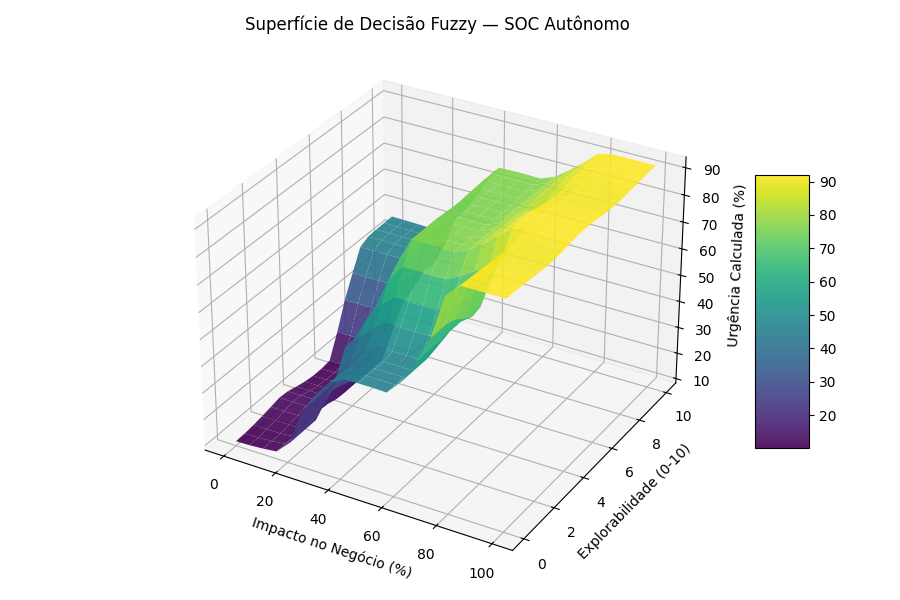

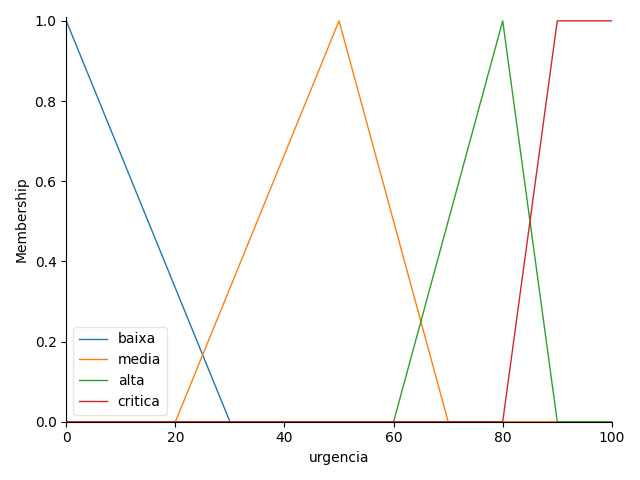

In [26]:
!python engine.py
!python model.py

from IPython.display import Image, display
display(Image('results/superficie_decisao.png'))
display(Image('results/membership_functions.png'))

## 3. execução do pytest




In [23]:
!pytest -v -W ignore::DeprecationWarning --cov=engine --cov=model --cov-report=term-missing test_fuzzy_engine.py

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: cov-7.1.0, platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 4 items                                                              

test_fuzzy_engine.py::test_saida_dentro_do_universo PASSED               [ 25%]
test_fuzzy_engine.py::test_monotonicidade_impacto PASSED                 [ 50%]
test_fuzzy_engine.py::test_entradas_invalidas_disparam_erro PASSED       [ 75%]
test_fuzzy_engine.py::test_latencia_inferencia FAILED                    [100%]

=================================== FAILURES ===================================
___________________________ test_latencia_inferencia ___________________________

simulador = <skfuzzy.control.controlsystem.ControlSystemSimulation object at 0x7b8c2a6be9e0>

    def test_latencia_inferencia(simulador):
  

In [27]:
# Latência (saída do console)
!pytest -s -W ignore::DeprecationWarning test_fuzzy_engine.py

============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0
rootdir: /content
plugins: cov-7.1.0, platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 4 items                                                              

test_fuzzy_engine.py ...
Tempo médio por inferência: 4.011 ms
.

============================== 4 passed in 1.66s ===============================


## 4. sistema de triagem de UTI

In [25]:
!python uti_triagem.py 2>/dev/null
!pytest -v -W ignore::DeprecationWarning --cov=uti_triagem test_uti_triagem.py

Sistema de UTI instanciado com sucesso!
FC= 75 bpm | SpO2=98% => Risco 11.67%
FC= 75 bpm | SpO2=95% => Risco 35.71%
FC= 75 bpm | SpO2=89% => Risco 85.57%
FC= 45 bpm | SpO2=98% => Risco 50.00%
FC=120 bpm | SpO2=92% => Risco 85.91%
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: cov-7.1.0, platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 4 items                                                              

test_uti_triagem.py::test_paciente_saudavel_baixo_risco PASSED           [ 25%]
test_uti_triagem.py::test_salto_nao_linear_queda_spo2 PASSED             [ 50%]
test_uti_triagem.py::test_validacao_limites_fisiologicos PASSED          [ 75%]
test_uti_triagem.py::test_sem_lacuna_de_cobertura PASSED                 [100%]

================================ tests coverage ==========================